# Spanish News Headlines: Scraping and Sentiment

Scrapes the front-page headlines of two Spanish newspapers, **El Mundo** and **El País**, with Requests and BeautifulSoup, scores each headline with a Hugging Face Transformers sentiment pipeline, and compares the tone of both outlets.

> The CSS selectors match the layout of both websites when the notebook was run (January 2025). If a site changes its HTML, the selectors need updating.

In [29]:
# Step 1: Import the libraries
import requests
from bs4 import BeautifulSoup
import pandas as pd
from transformers import pipeline
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
# Step 2: Scraping function for headlines

def obtener_titulares(url, selector):
    response = requests.get(url)
    soup = BeautifulSoup(response.content, 'html.parser')
    titulares = [tit.text.strip() for tit in soup.select(selector)]
    return titulares

# URLs and CSS selectors for each newspaper
urls = {
    "El Mundo": {
        "url": "https://www.elmundo.es/",
        "selector": "h2.ue-c-cover-content__headline"
    },
    "El País": {
        "url": "https://elpais.com/",
        "selector": "h2.c_t"
    }
}

In [31]:
# Step 3: Extract the headlines
all_titulares = {}
for nombre, info in urls.items():
    try:
        all_titulares[nombre] = obtener_titulares(info["url"], info["selector"])
    except Exception as e:
        print(f"Error obteniendo titulares de {nombre}: {e}")

In [32]:
# Step 4: Build a DataFrame with one row per headline
rows = []
for fuente, titulares in all_titulares.items():
    for titular in titulares:
        rows.append({"Fuente": fuente, "Titular": titular})

data = pd.DataFrame(rows)
print("Primeras filas del conjunto de titulares:")
data

Primeras filas del conjunto de titulares:


,Fuente,Titular
0,El Mundo,La fuga entre bloques ya no es imposible: la d...
1,El Mundo,El Gobierno arranca el año hundido y PP-Vox co...
2,El Mundo,El quid está en la abstención
3,El Mundo,Los Reyes Magos llevan la ilusión a los niños ...
4,El Mundo,Domingo de magia y regalos en las calles de to...
...,...,...
176,El País,“La doble moral de ofenderse por una estampita...
177,El País,Recuperan cuatro meses después estas palabras ...
178,El País,Estos son los 7 canteranos que se lleva Ancelo...
179,El País,Perplexity contra Google. David frente a Golia...


In [33]:
# Step 5: Sentiment analysis
# Hugging Face sentiment-analysis pipeline
sentiment_pipeline = pipeline("sentiment-analysis")

# Label and score each headline
data["Sentimiento"] = data["Titular"].apply(lambda x: sentiment_pipeline(x)[0]['label'])
data["Puntaje"] = data["Titular"].apply(lambda x: sentiment_pipeline(x)[0]['score'])

In [34]:
# Step 6: Visualize the results
# Sentiment distribution per newspaper
sentiment_summary = data.groupby(["Fuente", "Sentimiento"]).size().unstack().fillna(0)

print("Distribución de sentimientos por fuente:")
sentiment_summary

Distribución de sentimientos por fuente:


Sentimiento,NEGATIVE,POSITIVE
Fuente,,
El Mundo,33,16
El País,86,46


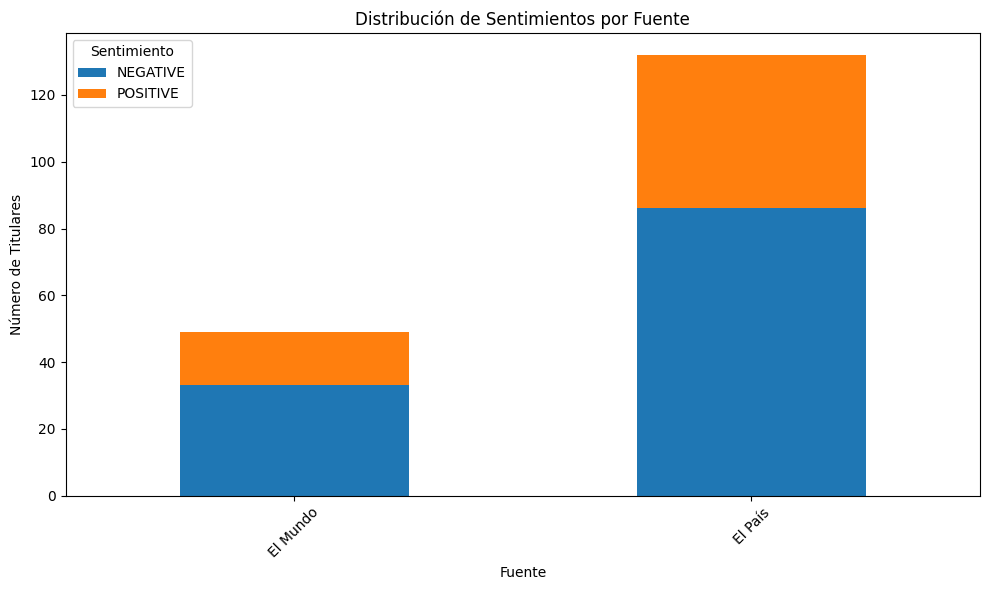

In [35]:
# Stacked bar chart
sentiment_summary.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title("Distribución de Sentimientos por Fuente")
plt.xlabel("Fuente")
plt.ylabel("Número de Titulares")
plt.xticks(rotation=45)
plt.legend(title="Sentimiento")
plt.tight_layout()
plt.show()

In [36]:
# Step 7: Average sentiment score (model confidence) per newspaper
mean_scores = data.groupby("Fuente")["Puntaje"].mean()
print("Promedio de puntajes de sentimiento por fuente:")
mean_scores

Promedio de puntajes de sentimiento por fuente:


,Puntaje
Fuente,
El Mundo,0.868294
El País,0.870878


## Results

181 headlines were scraped: 49 from El Mundo and 132 from El País.

| Newspaper | Negative | Positive | % negative | Average score |
|---|---|---|---|---|
| El Mundo | 33 | 16 | 67% | 0.868 |
| El País | 86 | 46 | 65% | 0.871 |

- **Both outlets lean negative:** about two thirds of the headlines in each newspaper were labelled negative, a possible sign of thematic bias towards unfavourable news.
- **Similar tone:** the share of negative headlines and the average score (the model's confidence in its label) are almost identical, so this sample shows no clear difference in tone between the two newspapers.

**Limitation:** the default pipeline (`distilbert-base-uncased-finetuned-sst-2-english`) is trained on English text, so its labels on Spanish headlines are only indicative. A multilingual or Spanish model would give more reliable results.